# The Euler cantilever, displacement and mixed: two mirror images

Companion notebook to *Variational Methods in Computational Mechanics* (S. Vidoli),
Chapter 7, Section "From Penalty to Lagrange Multiplier", Example "Three Mixed Formulations of the Euler Beam".

A cantilever of unit length, $EI = 1$, clamped at $x = 0$, under a uniform load $p = 1$. We solve it twice:
- **displacement formulation**, $\min_w \int \big(\tfrac{1}{2}(w'')^2 - p\,w\big)$, with cubic Hermite elements;
- **second mixed form**, $\min_w \max_m \int \big(-m'w' - \tfrac{1}{2}m^2 - p\,w\big)$ with $w(0) = 0$, $m(1) = 0$,
  with linear elements for both $w$ and the bending moment $m$.

The exact solution is $w = x^2(6 - 4x + x^2)/24$, $m = w'' = (1 - x)^2/2$.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# ---------------------------------------------------------------- PARAMETERS
N = 4            # number of elements
# ---------------------------------------------------------------------------

x = np.linspace(0, 1, N + 1); h = 1 / N
w_ex = lambda s: s**2 * (6 - 4*s + s**2) / 24
m_ex = lambda s: (1 - s)**2 / 2

## 1. Hermite elements

Unknowns: deflection and rotation at the nodes. The bending moment $w_h''$ is linear on each element, and jumps
at the nodes.

In [2]:
Ke = np.array([[12, 6*h, -12, 6*h], [6*h, 4*h*h, -6*h, 2*h*h],
               [-12, -6*h, 12, -6*h], [6*h, 2*h*h, -6*h, 4*h*h]]) / h**3
fe = h * np.array([.5, h/12, .5, -h/12])
K = np.zeros((2*N + 2,) * 2); f = np.zeros(2*N + 2)
for e in range(N):
    K[2*e:2*e+4, 2*e:2*e+4] += Ke; f[2*e:2*e+4] += fe
U = np.r_[0, 0, np.linalg.solve(K[2:, 2:], f[2:])]
wH = U[0::2]
# moment at the two ends of each element: w'' of the Hermite cubic
mH = [((np.array([-6, -4*h, 6, -2*h]) / h**2) @ U[2*e:2*e+4],
       (np.array([6, 2*h, -6, 4*h]) / h**2) @ U[2*e:2*e+4]) for e in range(N)]

## 2. Mixed form, linear $w$ and $m$

The stationarity conditions give the symmetric, indefinite system
$\begin{pmatrix} 0 & \mathbf{B} \\ \mathbf{B}^\top & -\mathbf{M} \end{pmatrix}
 \begin{pmatrix} \mathbf{w} \\ \mathbf{m} \end{pmatrix} = \begin{pmatrix} \mathbf{f} \\ 0 \end{pmatrix}$,
with $\mathbf{B} = -\mathbf{S}$ the stiffness matrix of linear elements (rows: $w$, columns: $m$) and
$\mathbf{M}$ their mass matrix.

In [3]:
I = np.eye(N + 1)
S = (2*I - np.eye(N + 1, k=1) - np.eye(N + 1, k=-1)) / h; S[0, 0] = S[N, N] = 1 / h
M = h / 6 * (4*I + np.eye(N + 1, k=1) + np.eye(N + 1, k=-1)); M[0, 0] = M[N, N] = h / 3
fl = np.full(N + 1, h); fl[[0, N]] = h / 2
iw, im = np.r_[1:N + 1], np.r_[0:N]                  # w(0) = 0, m(1) = 0
B = -S[np.ix_(iw, im)]
A = np.block([[np.zeros((N, N)), B], [B.T, -M[np.ix_(im, im)]]])
V = np.linalg.solve(A, np.r_[fl[iw], np.zeros(N)])
wM, mM = np.r_[0, V[:N]], np.r_[V[N:], 0]

print("                    displacement (Hermite)     mixed (linear w, m)")
print(f"max nodal error w : {np.abs(wH - w_ex(x)).max():.2e}                  {np.abs(wM - w_ex(x)).max():.2e}"
      f"   (h^2/24 = {h**2/24:.2e})")
eH = max(max(abs(a - m_ex(x[e])), abs(b - m_ex(x[e+1]))) for e, (a, b) in enumerate(mH))
print(f"max nodal error m : {eH:.2e}"
      f"   (h^2/12 = {h**2/12:.2e})    {np.abs(mM - m_ex(x)).max():.2e}")

                    displacement (Hermite)     mixed (linear w, m)
max nodal error w : 2.78e-15                  2.60e-03   (h^2/24 = 2.60e-03)
max nodal error m : 5.21e-03   (h^2/12 = 5.21e-03)    0.00e+00


Each method is exact where the other one errs. Hermite elements give exact nodal displacements, and moments off
by $h^2/12$ at the nodes; the mixed form gives exact nodal moments, and displacements off by $h^2 x^2/24$:
the deflection of the cantilever under a *uniform* extra moment $h^2/12$.

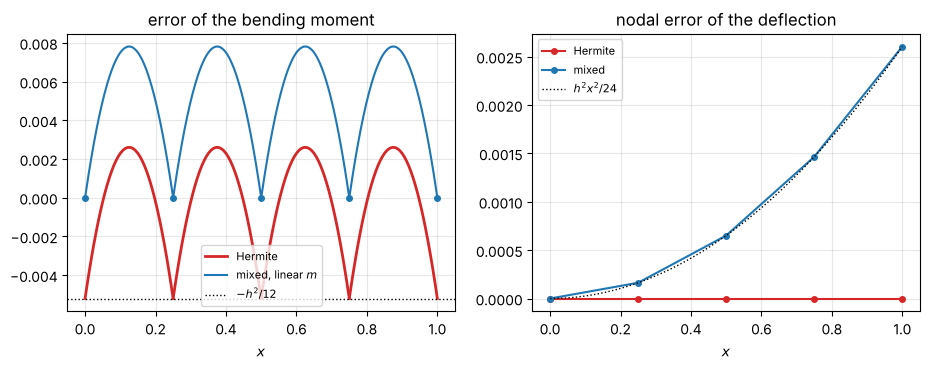

In [4]:
s = np.linspace(0, 1, 401)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
for e, (a, b) in enumerate(mH):
    se = np.linspace(x[e], x[e+1], 41)
    ax[0].plot(se, a + (b - a) * (se - x[e]) / h - m_ex(se), "C3", lw=2, label="Hermite" if e == 0 else None)
ax[0].plot(s, np.interp(s, x, mM) - m_ex(s), "C0", label="mixed, linear $m$")
ax[0].plot(x, mM - m_ex(x), "C0o", ms=4)
ax[0].axhline(-h**2 / 12, color="k", ls=":", lw=1, label="$-h^2/12$")
ax[0].set_title("error of the bending moment"); ax[0].legend(fontsize=8)
ax[1].plot(x, wH - w_ex(x), "C3o-", ms=4, label="Hermite")
ax[1].plot(x, wM - w_ex(x), "C0o-", ms=4, label="mixed")
ax[1].plot(s, h**2 * s**2 / 24, "k:", lw=1, label="$h^2 x^2/24$")
ax[1].set_title("nodal error of the deflection"); ax[1].legend(fontsize=8)
for a in ax: a.set_xlabel("$x$"); a.grid(alpha=0.3)
plt.show()

## Things to try

1. Double `N` a few times: both errors fall like $h^2$, and both keep their shape.
2. Replace the uniform load with a force at the tip (`fl[:] = 0; fl[N] = 1`, and in Hermite `f[:] = 0; f[-2] = 1`;
   the exact moment is $1 - x$, the deflection $x^2(3 - x)/6$). Now the moment is linear: what happens to the
   errors of both methods?
3. Write the third mixed form of the example, $\int (m''w - \tfrac{1}{2}m^2 - p\,w)$: which elements does it need
   for $m$?